# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Kim 2020's malignant manifold is **non-branching**: the gastrulation / somitogenesis / neural-crest
developmental signatures form a single monotone gradient (Gast decays, Crest rises to a terminal pole;
pSom is the flat body) rather than a hub radiating into two competing arms. A PPT **tree** fit here
carves the dense 2D cloud into 5–7 "branch nodes" that all sit at the centre of one blob and share
identical module identity (every tip: Gast≈−0.04, pSom≈+0.05, Crest≈−0.03) — spurious geometry, not
biology. The honest topology is therefore a **principal curve**, fit fold-free with ElPiGraph and
rooted at the developmental origin.

Deliverables: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding (re-embedding a
linear compartment folds it; Kürten §4). Score the three embryonic signatures against the shared
**union** control pool and **graph-smooth** them (knn-connectivity averaging) to read geography rather
than 10x per-cell dropout. Raw scores are retained for the deliverable signature UMAPs (03).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 10512 cells
UMAP aspect ratio (major/minor std): 1.24
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present


### Scope decision — whole manifold vs Embryonic lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling lobe (Kürten case, where scoping is
justified) or spans both lobes (Bischoff/Sun case, keep the whole manifold). Two facts settle it: (i)
the smoothed developmental signatures form ONE axis (Gast opposite Crest, both spanning both lobes);
(ii) the two lobes have **identical** module means — they differ only in cycling fraction, and the
modules are **orthogonal to proliferation** (|rho vs g2m| < 0.15). The cycling lobe is a
proliferation state, not a separate developmental fate -> keep the whole manifold.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling']].mean().round(3).to_string())
print('\nproliferation confound check (module vs g2m_score):')
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(adata.obs['g2m_score'], adata.obs[m]); print(f'  {m} vs g2m: rho = {rho:+.2f}')
print('-> developmental axis orthogonal to the proliferation split; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.11
  Crest_sm vs Gast_sm: r = -0.55
  Crest_sm vs pSom_sm: r = -0.41

per-compartment smoothed developmental means:
                   Gast_sm  pSom_sm  Crest_sm  cycling
compartment                                           
Embryonic           -0.040    0.056    -0.027    0.063
Cycling/Metabolic   -0.046    0.051    -0.020    0.607

proliferation confound check (module vs g2m_score):
  Gast vs g2m: rho = -0.12
  pSom vs g2m: rho = +0.04
  Crest vs g2m: rho = +0.02
-> developmental axis orthogonal to the proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph) — fold-free
`Nodes/epg_lambda/epg_mu` give a fold-free monotone backbone. A **node self-approach ratio > 1**
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself; `forks == 0` certifies it is a single curve, not a tree.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('topology: single fold-free principal curve confirmed')

curve: 2 tips, 0 forks | fold self-approach ratio = 2.80 (>1 = fold-free)
topology: single fold-free principal curve confirmed


### Derive the root (developmental order, data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Neural crest is developmentally **late**, so it is the terminus, never the root; the root is never a
proliferation state. Pseudotime then flows origin -> Crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
rho_c,_ = spearmanr(t, sub.obs['cycling'].astype(float)); print(f'  cycling: rho={rho_c:+.3f}')

tip 0: Gast=-0.0307 pSom=+0.0549 Crest=-0.0306
tip 2: Gast=-0.0491 pSom=+0.0551 Crest=-0.0209
derived root = tip 0 (Gast/pSom-high, Crest-low)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.545 p=0.0e+00
  pSom_sm: rho=+0.090 p=3.5e-20
  Crest_sm: rho=+0.476 p=0.0e+00
  cycling: rho=+0.409


### Reorient to house style + continuity cross-check
Re-use the house orientation `X_umap_lin` derived in 01 (developmental origin on the left). Assert it
is pseudotime-consistent (corr(x_lin, t) > 0.5) so the panel reads left→right along the trajectory;
compare the variance-axis and pseudotime-axis to confirm they agree.

In [7]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_,_,vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.93
variance-axis vs pseudotime-axis disagreement = 7.9deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)
`manifold.pdf`: pseudotime on the house orientation, `figsize=(3.5,1.5)`, `size=30`.

saved manifold.h5ad + manifold.pdf


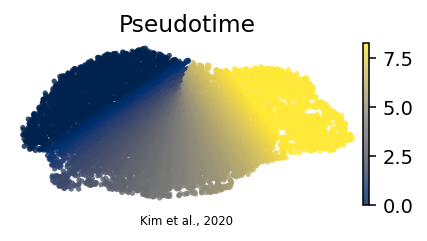

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')